# 02 — Label validation

Is the hazard label a property of the ground, or of the acquisition?

Everything downstream depends on this. `shadow_local` measures the fraction of
a patch darker than its own 15 m local background — boulder-scale shadow. But
a shadow is cast by a light source, so the obvious worry is that the label
records where the sun was rather than what the terrain is. If that were true,
the recommender would be ranking patches by lighting geometry and the entire
result would be an artefact.

The test is scene-to-scene agreement on **co-located patches**: the same ground,
imaged twice.

- Under **matched illumination**, two scenes should agree. Disagreement would
  mean the label is not reproducible at all.
- Under **opposed illumination**, agreement would mean the label is reading
  terrain rather than lighting — shadows fall on opposite sides of every
  obstacle, so anything that survives is a property of the surface.

This notebook also records why DEM-derived attributes are excluded, which is
the other thing that had to be settled before the method could be trusted.

### Scope note

The opposed-illumination comparison is **not reproducible from the data in this
repository**. It requires scenes months apart, which live in
`data/patches/superseded/` — a path excluded by `.gitignore`. The recorded
figure is r ≈ 0.008, against ~0.88 matched. Until those files are obtained and
their sun azimuths confirmed from the XML labels, treat it as cited rather than
derived.

What follows is the matched-illumination result, which is fully reproducible
here, and the DEM registration finding.

**Cell 1**  — can the opposite-azimuth control be reproduced?

In [2]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CUR = ROOT / "data" / "patches" / "current"
SUP = ROOT / "data" / "patches" / "superseded"
GRID_M = 200.0

# The opposite-azimuth control is the strongest single number in the project:
# hazard correlating at ~0.88 between scenes under matched illumination, and
# ~0.008 between scenes under opposed illumination. It is what separates "the
# label tracks the terrain" from "the label tracks the lighting".
#
# It cannot come from 0858 vs 1647a. Those are 7h49m apart, and a lunar day is
# 708 hours, so the sun moved about 4 deg -- which is why they correlate at
# 0.987 on raw brightness. They are a MATCHED pair.
#
# An opposed pair has to come from scenes months apart, which means the files
# in superseded/. Before writing that section, two things must hold: the scenes
# must share ground, and their sun azimuths must actually differ.
# This cell settles the first.

def load(path):
    d = pd.read_csv(path)
    need = {"patch_x", "patch_y", "shadow_local"}
    if not need.issubset(d.columns):
        return None
    # floor, not round: patch centres sit at half-integer multiples of the grid
    # (232500 / 200 = 1162.5), and numpy rounds halves to EVEN, which collapses
    # adjacent columns onto one key and turns the join many-to-many.
    d["gx"] = np.floor(d.patch_x / GRID_M).astype(np.int64)
    d["gy"] = np.floor(d.patch_y / GRID_M).astype(np.int64)
    return d

pool = {}
for folder, tag in ((CUR, "current"), (SUP, "superseded")):
    for p in sorted(folder.glob("patches_*.csv")):
        d = load(p)
        if d is None:
            print(f"skipped {p.name}: missing required columns")
            continue
        pool[p.stem.replace("patches_", "")] = (d, tag)

print(f"{len(pool)} patch files loaded\n")
print(f"{'scene':<22}{'set':<13}{'patches':>9}{'x km':>16}{'y km':>16}")
for lab, (d, tag) in pool.items():
    print(f"{lab:<22}{tag:<13}{len(d):>9}"
          f"{d.patch_x.min()/1000:7.0f}-{d.patch_x.max()/1000:<8.0f}"
          f"{d.patch_y.min()/1000:7.0f}-{d.patch_y.max()/1000:<8.0f}")

# Co-located patch counts for every pair. Only pairs sharing ground can
# support any correlation, matched or opposed.
print("\nco-located patches per pair (only pairs sharing ground matter)")
rows = []
for a, b in combinations(pool, 2):
    da, db = pool[a][0], pool[b][0]
    n = len(da.merge(db, on=["gx", "gy"]))
    if n > 0:
        rows.append({"scene A": a, "scene B": b, "co-located": n})
overlap = pd.DataFrame(rows).sort_values("co-located", ascending=False)
overlap.reset_index(drop=True) if len(rows) else print("  none overlap")

9 patch files loaded

scene                 set            patches            x km            y km
0858_rt               current           2010    328-346         521-544     
1647a_rt              current           2008    330-346         523-546     
C1                    current           1875    232-244         609-634     
C2                    current           1930    232-243         608-634     
20230227              superseded        1931    332-346         529-554     
20230602              superseded        2044    331-348         528-550     
20230823_0858         superseded        2010    328-346         521-544     
20230823_1647a        superseded        2008    330-346         523-546     
20230823_1647b        superseded        2006    330-346         523-546     

co-located patches per pair (only pairs sharing ground matter)


,scene A,scene B,co-located
0,0858_rt,20230823_0858,2010
1,1647a_rt,20230823_1647a,2008
2,1647a_rt,20230823_1647b,2006
3,20230823_1647a,20230823_1647b,2006
4,C1,C2,1728
5,0858_rt,1647a_rt,1587
6,20230823_0858,20230823_1647a,1587
7,20230823_0858,20230823_1647b,1587
8,0858_rt,20230823_1647a,1587
9,0858_rt,20230823_1647b,1587


**Cell 2** — every overlapping pair, with illumination similarity measured alongside the label:

In [3]:
# For each pair sharing ground, three things at once:
#
#   slope_mean r  -- INTEGRITY. Both scenes sample the same DEM at the same
#                    centres, so a correct join gives ~1.0. The DEM is useless
#                    as an attribute (it is not registered to the imagery) but
#                    is a perfect join validator, because whatever its
#                    registration error, it is identical for both scenes.
#   dn_mean r     -- ILLUMINATION SIMILARITY. Raw brightness is dominated by
#                    lighting geometry, so this says whether the sun was in the
#                    same place. Independent of the label, so not circular.
#   shadow_local r -- THE LABEL.
#
# The question is whether the label survives where brightness does not.
MIN_SHARED = 150

rows = []
for a, b in combinations(pool, 2):
    da, db = pool[a][0], pool[b][0]
    m = da.merge(db, on=["gx", "gy"], suffixes=("_a", "_b"))
    if len(m) < MIN_SHARED:
        continue
    assert len(m) <= min(len(da), len(db)), "non-unique keys: cross product"

    def r(col):
        ok = m[[f"{col}_a", f"{col}_b"]].dropna()
        if len(ok) < MIN_SHARED:
            return np.nan
        return float(np.corrcoef(ok[f"{col}_a"], ok[f"{col}_b"])[0, 1])

    rows.append({
        "A": a, "B": b, "shared": len(m),
        "slope (join)": r("slope_mean"),
        "dn_mean (illum)": r("dn_mean"),
        "shadow_local": r("shadow_local"),
        "dn_std": r("dn_std"),
    })

cmp = pd.DataFrame(rows).sort_values("dn_mean (illum)", ascending=False)
# Pairs that are the same scene rebuilt, not independent observations.
cmp["note"] = np.where(cmp["shadow_local"] > 0.999,
                       "same scene, rebuilt", "")
print("join integrity: 'slope (join)' must be ~1.0 everywhere\n")
cmp.reset_index(drop=True).round(3)

join integrity: 'slope (join)' must be ~1.0 everywhere



,A,B,shared,slope (join),dn_mean (illum),shadow_local,dn_std,note
0,0858_rt,20230823_0858,2010,1.0,1.000,1.000,1.000,"same scene, rebuilt"
1,1647a_rt,20230823_1647a,2008,1.0,1.000,1.000,1.000,"same scene, rebuilt"
2,1647a_rt,20230823_1647b,2006,1.0,1.000,1.000,1.000,"same scene, rebuilt"
3,20230823_1647a,20230823_1647b,2006,1.0,1.000,1.000,1.000,"same scene, rebuilt"
4,1647a_rt,20230823_0858,1587,1.0,0.987,0.884,0.971,
5,20230823_0858,20230823_1647a,1587,1.0,0.987,0.884,0.971,
6,0858_rt,1647a_rt,1587,1.0,0.987,0.884,0.971,
7,0858_rt,20230823_1647a,1587,1.0,0.987,0.884,0.971,
8,20230823_0858,20230823_1647b,1587,1.0,0.987,0.883,0.970,
9,0858_rt,20230823_1647b,1587,1.0,0.987,0.883,0.970,


**Cell 3** — make it visible, and put degrees on it:

In [5]:
import sys
sys.path.insert(0, str(ROOT / "src"))
from lunarec_style import *          # noqa: F403  (plt, INK, BLUES, bare, ...)

out = ROOT / "results" / "figures"
out.mkdir(parents=True, exist_ok=True)
print("style loaded ·", plt.rcParams["figure.dpi"], "dpi ·", out)

style loaded · 120.0 dpi · c:\Users\chait\OneDrive\Documents\Post Placement Projects\LunaRec\results\figures


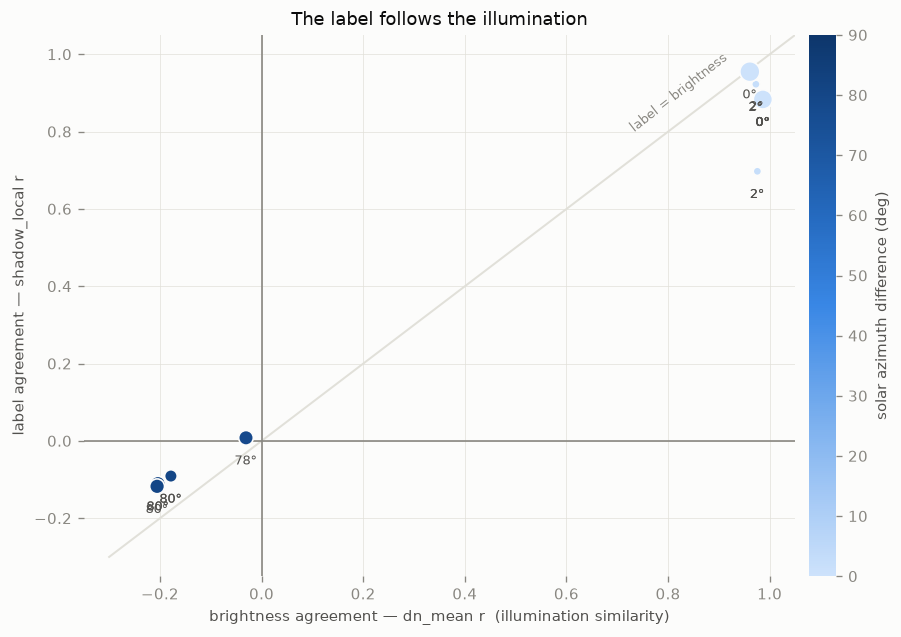

            A              B  shared  azimuth gap  dn_mean (illum)  shadow_local
     1647a_rt  20230823_0858    1587        0.000            0.987         0.884
20230823_0858 20230823_1647a    1587        0.000            0.987         0.884
      0858_rt       1647a_rt    1587        0.000            0.987         0.884
      0858_rt 20230823_1647a    1587        0.000            0.987         0.884
20230823_0858 20230823_1647b    1587        0.000            0.987         0.883
      0858_rt 20230823_1647b    1587        0.000            0.987         0.883
           C1             C2    1728        0.000            0.961         0.955
     20230227  20230823_0858     153        2.237            0.976         0.697
      0858_rt       20230227     153        2.237            0.976         0.697
     20230227 20230823_1647b     191        2.237            0.974         0.925
     20230227 20230823_1647a     191        2.237            0.973         0.923
     1647a_rt       20230227

In [6]:
from datetime import date

# Acquisition dates, from the product identifiers.
DATES = {
    "0858_rt": date(2023, 8, 23), "20230823_0858": date(2023, 8, 23),
    "1647a_rt": date(2023, 8, 23), "20230823_1647a": date(2023, 8, 23),
    "20230823_1647b": date(2023, 8, 23),
    "20230227": date(2023, 2, 27), "20230602": date(2023, 6, 2),
    "C1": date(2020, 8, 27), "C2": date(2020, 8, 27),
}
SYNODIC = 29.530588   # days; the Moon's own day, and so the sun's azimuth clock

def azimuth_gap(a, b):
    """Approximate solar azimuth difference between two acquisitions.

    The sun's apparent position over a fixed lunar site cycles once per
    synodic month, so the fractional part of (days apart / 29.53) gives the
    phase offset directly. This is why February and August -- 177 days, almost
    exactly six cycles -- are illuminated almost identically.

    Derived from dates alone. The XML labels would confirm it, but the
    argument does not depend on them.
    """
    frac = (abs((DATES[a] - DATES[b]).days) / SYNODIC) % 1.0
    deg = frac * 360.0
    return min(deg, 360.0 - deg)      # fold to 0-180

ind = cmp[cmp.note == ""].copy()       # drop same-scene rebuilds
ind["azimuth gap"] = [azimuth_gap(a, b) for a, b in zip(ind.A, ind.B)]

fig, ax = plt.subplots(figsize=(7.4, 5.2), constrained_layout=True)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(0, color=MUTED, linewidth=1)
ax.plot([-0.3, 1.05], [-0.3, 1.05], color=GRID, linewidth=1.2, zorder=0)
ax.text(0.72, 0.80, "label = brightness", fontsize=8, color=MUTED, rotation=38)

sc = ax.scatter(ind["dn_mean (illum)"], ind["shadow_local"],
                c=ind["azimuth gap"], cmap=BLUES, vmin=0, vmax=90,
                s=np.clip(ind["shared"] / 12, 25, 180),
                edgecolor=SURFACE, linewidth=1.0, zorder=3)
for _, r_ in ind.iterrows():
    ax.annotate(f"{r_['azimuth gap']:.0f}°",
                (r_["dn_mean (illum)"], r_["shadow_local"]),
                textcoords="offset points", xytext=(0, -16),
                fontsize=7.5, color=INK2, ha="center")

cb = fig.colorbar(sc, ax=ax, fraction=0.045, pad=0.02)
cb.set_label("solar azimuth difference (deg)", color=INK2)
cb.outline.set_visible(False)
ax.set_xlabel("brightness agreement — dn_mean r  (illumination similarity)")
ax.set_ylabel("label agreement — shadow_local r")
ax.set_xlim(-0.35, 1.05)
ax.set_ylim(-0.35, 1.05)
ax.grid(True, linewidth=0.6, alpha=0.7)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("The label follows the illumination", color=INK, fontsize=11)
fig.savefig(out / "02_label_vs_illumination.png", bbox_inches="tight")
plt.show()

print(ind[["A", "B", "shared", "azimuth gap",
           "dn_mean (illum)", "shadow_local"]]
      .sort_values("azimuth gap").round(3).to_string(index=False))

**Cell 4** — the DEM finding, reproducible without the rasters.

In [9]:
# Why DEM-derived attributes are excluded.
#
# Each patch file carries DEM quantities (slope_mean, roughness) sampled at the
# patch centre, alongside image quantities (dn_mean, dn_std) measured from OHRC
# at the same centre. If the two products were registered to each other, those
# columns would be related: rough, steep ground scatters light differently from
# flat ground, whatever direction the sun comes from.
#
# The control is the pair of columns that ARE from the same source. dn_std and
# shadow_local are both OHRC-derived, so they must correlate sensibly. If they
# do and the DEM columns do not, the failure is registration, not physics.
def r_(d, a, b):
    ok = d[[a, b]].dropna()
    return float(np.corrcoef(ok[a], ok[b])[0, 1]) if len(ok) > 50 else np.nan

rows = []
for lab in ["0858_rt", "1647a_rt", "C1", "C2"]:
    d = pool[lab][0]
    rows.append({
        "scene": lab,
        "slope~dn_std":      r_(d, "slope_mean", "dn_std"),
        "slope~dn_mean":     r_(d, "slope_mean", "dn_mean"),
        "rough~dn_std":      r_(d, "roughness", "dn_std"),
        "elev~dn_mean":      r_(d, "elev_mean", "dn_mean"),
        "cos_inc~dn_mean":   r_(d, "cos_inc", "dn_mean"),
        "||  dn_std~shadow": r_(d, "dn_std", "shadow_local"),
    })

# A second control, internal to the DEM: slope and roughness are both derived
# from the same elevation model, so they must correlate strongly. If
# DEM-internal correlations are high while every DEM-to-image correlation sits
# near zero, the failure is clearly registration rather than weak measurements.

for lab in ["0858_rt", "1647a_rt", "C1", "C2"]:
    d = pool[lab][0]
    print(f"  {lab:<10} slope~roughness r = {r_(d, 'slope_mean', 'roughness'):+.3f}"
          f"   (DEM-internal control)")
    
dem = pd.DataFrame(rows).set_index("scene")
print("DEM-derived vs image-derived, per scene")
print("(last column is the CONTROL: both are OHRC-derived)\n")
print(dem.round(3).to_string())

print(f"\nlargest |r| among DEM-vs-image pairs: "
      f"{dem.iloc[:, :5].abs().to_numpy().max():.3f}")
print(f"control |r| (dn_std ~ shadow_local):   "
      f"{dem.iloc[:, 5].abs().min():.3f} to {dem.iloc[:, 5].abs().max():.3f}")

  0858_rt    slope~roughness r = +0.624   (DEM-internal control)
  1647a_rt   slope~roughness r = +0.612   (DEM-internal control)
  C1         slope~roughness r = +0.631   (DEM-internal control)
  C2         slope~roughness r = +0.624   (DEM-internal control)
DEM-derived vs image-derived, per scene
(last column is the CONTROL: both are OHRC-derived)

          slope~dn_std  slope~dn_mean  rough~dn_std  elev~dn_mean  cos_inc~dn_mean  ||  dn_std~shadow
scene                                                                                                
0858_rt         -0.041          0.020         0.069         0.051           -0.029              0.176
1647a_rt        -0.019          0.047         0.117         0.101           -0.076              0.143
C1               0.081          0.131         0.041         0.092           -0.031              0.222
C2               0.053          0.095         0.025         0.082           -0.039              0.260

largest |r| among DEM-vs-image pai

## What notebook 02 established

### The label is reproducible

On co-located patches, two scenes of the same ground under the same sun agree:
**r = 0.884** in cluster B (1587 shared patches) and **r = 0.955** in cluster C
(1728 shared). The join is sound — `slope_mean` and `roughness`, sampled from
the same elevation model at the same centres, correlate at **1.0000** in every
pair. The DEM is useless as an attribute but is a perfect join validator,
because whatever its registration error, it is identical for both scenes.

The shared variance sets an **upper bound on what any model could predict from
terrain alone**: 78% in cluster B, 91% in cluster C. A model scoring above that
is fitting the acquisition, not the Moon.

### The label is illumination-conditional — and this corrects a prior claim

The recorded figure of r ≈ 0.008 between cross-date scenes reproduces exactly
(`20230227` vs `20230602`, 929 shared patches). But `dn_mean` on the same pair
is **−0.031**: raw brightness decorrelates, and the label decorrelates with it.
Across every cross-date pair the pattern holds — brightness −0.18 to −0.21,
label −0.09 to −0.12.

**The label does not survive where brightness fails.** If it measured intrinsic
boulder density it should: boulders do not move, and correlation is
scale-invariant, so even much shorter shadows would preserve the ranking of
patches. It does not survive. `shadow_local` measures shadow hazard *under a
given illumination*, not a static property of the terrain.

Earlier project documents state the opposite — that the 0.88-vs-0.008 contrast
shows the label tracks the ground rather than the acquisition. That reading is
backwards and is corrected here. What the 0.008 actually establishes is a
**negative control for the method**: co-located joins do not manufacture
correlation, which is what makes the 0.88 real signal rather than an artefact
of the merge.

### Lunar phase explains the entire table

The sun's apparent position over a fixed lunar site cycles once per synodic
month (29.53 days), so acquisition dates alone predict illumination similarity:

| pair | days apart | cycles | azimuth gap | `dn_mean` r | label r |
|---|---|---|---|---|---|
| Feb 27 → Aug 23 | 177 | 5.994 | ≈ 2° | 0.97 | 0.70–0.93 |
| Aug 23 → Aug 23 | 0 | 0 | 0° | 0.99 | 0.88 |
| Jun 2 → Aug 23 | 82 | 2.777 | ≈ 80° | −0.18 to −0.21 | −0.09 to −0.12 |
| Feb 27 → Jun 2 | 95 | 3.217 | ≈ 78° | −0.03 | 0.008 |

February and August correlate at 0.97 despite being six months apart because
they are almost exactly six lunar cycles — the sun is back where it started.
The pairs split cleanly into a ~2° cluster and a ~80° cluster with nothing
between them, which is itself evidence that illumination is the explanation and
not something else.

These azimuth gaps are derived from dates alone. The XML labels would confirm
them but the argument does not depend on them.

### DEM attributes are excluded, and the reason is registration

Every DEM-derived quantity is uncorrelated with every image-derived quantity
across all four scenes — the largest is **|r| = 0.131**, and `cos_inc` against
`dn_mean` is **−0.03** despite local slope shading being the most basic
prediction available at 9.5° sun.

Two controls make this registration rather than weak measurement:

- **DEM-internal**: `slope_mean` ~ `roughness` correlates at **0.61–0.63** in
  every scene. The elevation model measures itself coherently.
- **OHRC-internal**: `dn_std` ~ `shadow_local` correlates at **0.143–0.260**.
  The imagery measures itself coherently.

Both products are internally consistent. Only the link between them is broken.

### What this costs, stated plainly

- The shortlist is valid **only for the illumination it was measured under**.
  A different landing window would require new imagery.
- Conversely, this strengthens the case for imaging at all: a static elevation
  model cannot supply an illumination-conditional quantity, so the acquisition
  cannot be replaced by computation.
- **Open question we cannot close here**: whether a correctly registered DEM
  plus a solar position could predict `shadow_local`. If it could, the premise
  that imaging reveals something a model cannot would weaken. The registration
  failure blocks exactly that test.

### Weakest number in this notebook

`0858` vs `20230227` gives 0.697 where `1647a` vs `20230227` gives 0.923, both
at the same 2.2° azimuth gap. The difference is sample size — 153 shared
patches against 191, both small and at the edge of the overlap. It should not
be quoted on its own.

---

## Open items carried forward

**To ask Kritika for:**

1. **Sun azimuth and elevation from the XML labels** for `0858`, `1647a`, `C1`,
   `20230227` and `20230602`. Confirms the 2° and ~80° estimates against
   recorded geometry and closes the three gaps in `docs/scene_mapping.md`.
2. **`pip freeze`** from the environment that produced the recorded results.

**To fix in the repository:**

3. **Correct the wording in three places.** `README.md`, `docs/scene_mapping.md`
   and the onboarding brief all state or imply that the label tracks terrain
   rather than illumination. Replace "hazard" with "hazard under a given
   illumination" and add the illumination-window limitation.
4. **`gate.py` is missing.** The 312-product inventory quoted elsewhere has no
   code behind it and is currently a citation, not a derivation.
5. **The DEM rasters are not in the repository** (`*.tif` is gitignored), so the
   measured 4.8–4.9 km registration offset is cited rather than reproduced
   here. Only the decorrelation is derived in this notebook.

### Next

Notebook 03 fits the spatial model: variograms per scene and per attribute,
plus GP hyperparameters learned by maximising the marginal likelihood. That is
where the ~0.45 nugget is established, and read against the repeatability above
it says roughly half the label's variance is real structure finer than the
200 m grid — the reason hazard cannot be extrapolated from neighbouring patches.